In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import ScalarFormatter
import seaborn as sns
from sklearn.decomposition import PCA
from scipy.stats import spearmanr

# data split + preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# UL models
from sklearn.mixture import GaussianMixture

# evaluation metrics
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
import time



DATASET_PATH = "datasets/exercise-C/CTC-SP2-1996-3.1-cln.swf.gz"

In this exercise, we will be applying clustering to characterize jobs in an HPC environment.
The dataset used is the Parallel Workloads Archive.

First, we will start with data exploration and trying to answer the following questions:
- What is the nature of the features and their distribution ?
    - Are the features on different scales ?
    - Are there any particular peaks ?
- How do features correlate and relate to each other ?
    - Are there any redandunt features ?
    - What is the accuracy of the time requested for a job compared to its runtime ?
    - Does effeciency vary ? knowing the runtime and the average time per processor
- Is there any grouping tendency in the data ?
- Does the job workload change over time ?

# Data Exploration

In [269]:
cols = ["job","submit","wait","runtime","procs_used","cpu_avg","mem_used",
        "procs_req","time_req","mem_req","status","user","group","app",
        "queue","partition","prev_job","think_time"]
df = pd.read_csv(DATASET_PATH, sep=r"\s+", comment=";", names=cols)
df.head()

,job,submit,wait,runtime,procs_used,cpu_avg,mem_used,procs_req,time_req,mem_req,status,user,group,app,queue,partition,prev_job,think_time
0,1,0,588530,937,306,142.0,-1,-1,35100,-1,1,97,-1,307,3,-1,-1,-1
1,2,164472,356587,75,17,2.0,-1,-1,300,-1,1,81,-1,195,3,-1,-1,-1
2,3,197154,459987,35268,306,32792.0,-1,-1,35100,-1,0,97,-1,307,3,-1,-1,-1
3,4,310448,50431,29493,64,28745.0,-1,-1,64800,-1,1,38,-1,38,1,-1,-1,-1
4,5,310541,50766,29063,64,28191.0,-1,-1,64800,-1,1,38,-1,69,1,-1,-1,-1


In [108]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 77222 entries, 0 to 77221
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   job         77222 non-null  int64  
 1   submit      77222 non-null  int64  
 2   wait        77222 non-null  int64  
 3   runtime     77222 non-null  int64  
 4   procs_used  77222 non-null  int64  
 5   cpu_avg     77222 non-null  float64
 6   mem_used    77222 non-null  int64  
 7   procs_req   77222 non-null  int64  
 8   time_req    77222 non-null  int64  
 9   mem_req     77222 non-null  int64  
 10  status      77222 non-null  int64  
 11  user        77222 non-null  int64  
 12  group       77222 non-null  int64  
 13  app         77222 non-null  int64  
 14  queue       77222 non-null  int64  
 15  partition   77222 non-null  int64  
 16  prev_job    77222 non-null  int64  
 17  think_time  77222 non-null  int64  
dtypes: float64(1), int64(17)
memory usage: 10.6 MB


In [109]:
df.describe()

,job,submit,wait,runtime,procs_used,cpu_avg,mem_used,procs_req,time_req,mem_req,status,user,group,app,queue,partition,prev_job,think_time
count,77222.000000,7.722200e+04,7.722200e+04,77222.000000,77222.000000,77222.000000,77222.0,77222.0,77222.000000,77222.0,77222.000000,77222.000000,77222.0,77222.000000,77222.000000,77222.0,77222.0,77222.0
mean,39413.146034,1.445522e+07,2.553998e+04,11277.124343,10.985250,10251.879594,-1.0,-1.0,24396.649323,-1.0,0.784142,223.644428,-1.0,4146.747158,1.081583,-1.0,-1.0,-1.0
std,23151.954485,8.267368e+06,9.361431e+04,18281.552920,24.504365,17505.600828,0.0,0.0,26335.883124,0.0,0.411419,176.032246,0.0,3607.920069,0.396238,0.0,0.0,0.0
min,1.000000,0.000000e+00,1.000000e+00,0.000000,1.000000,-1.000000,-1.0,-1.0,-1.000000,-1.0,0.000000,1.000000,-1.0,1.000000,1.000000,-1.0,-1.0,-1.0
25%,19306.250000,7.326795e+06,2.100000e+01,111.000000,1.000000,11.000000,-1.0,-1.0,900.000000,-1.0,1.000000,70.000000,-1.0,925.000000,1.000000,-1.0,-1.0,-1.0
50%,38611.500000,1.436746e+07,2.197000e+03,1113.500000,3.000000,669.000000,-1.0,-1.0,10800.000000,-1.0,1.000000,181.000000,-1.0,3385.000000,1.000000,-1.0,-1.0,-1.0
75%,59996.750000,2.126433e+07,2.030700e+04,14122.750000,10.000000,11792.250000,-1.0,-1.0,57600.000000,-1.0,1.000000,354.000000,-1.0,7576.000000,1.000000,-1.0,-1.0,-1.0
max,79302.000000,2.929906e+07,7.231448e+06,71998.000000,336.000000,135985.000000,-1.0,-1.0,64800.000000,-1.0,1.000000,679.000000,-1.0,12315.000000,4.000000,-1.0,-1.0,-1.0


## 1. Feature Visualization

	**Col name	Official SWF field**
- 1	job	Job Number	
- 2	submit	Submit Time	seconds from the start of the log
- 3	wait	Wait Time	seconds
- 4	runtime	Run Time	seconds (wall-clock)
- 5	procs_used	Number of Allocated Processors	
- 6	cpu_avg	Average CPU Time Used	seconds, per processor
- 7	mem_used	Used Memory	KB, per processor
- 8	procs_req	Requested Number of Processors	
- 9	time_req	Requested Time	seconds (the user’s runtime estimate)
- 10	mem_req	Requested Memory	KB, per processor
- 11	status	Status	1 = completed, 0 = failed, 5 = cancelled
- 12	user	User ID	anonymized number
- 13	group	Group ID	
- 14	app	Executable (Application) Number	
- 15	queue	Queue Number	
- 16	partition	Partition Number	
- 17	prev_job	Preceding Job Number	
- 18	think_time	Think Time from Preceding Job	seconds

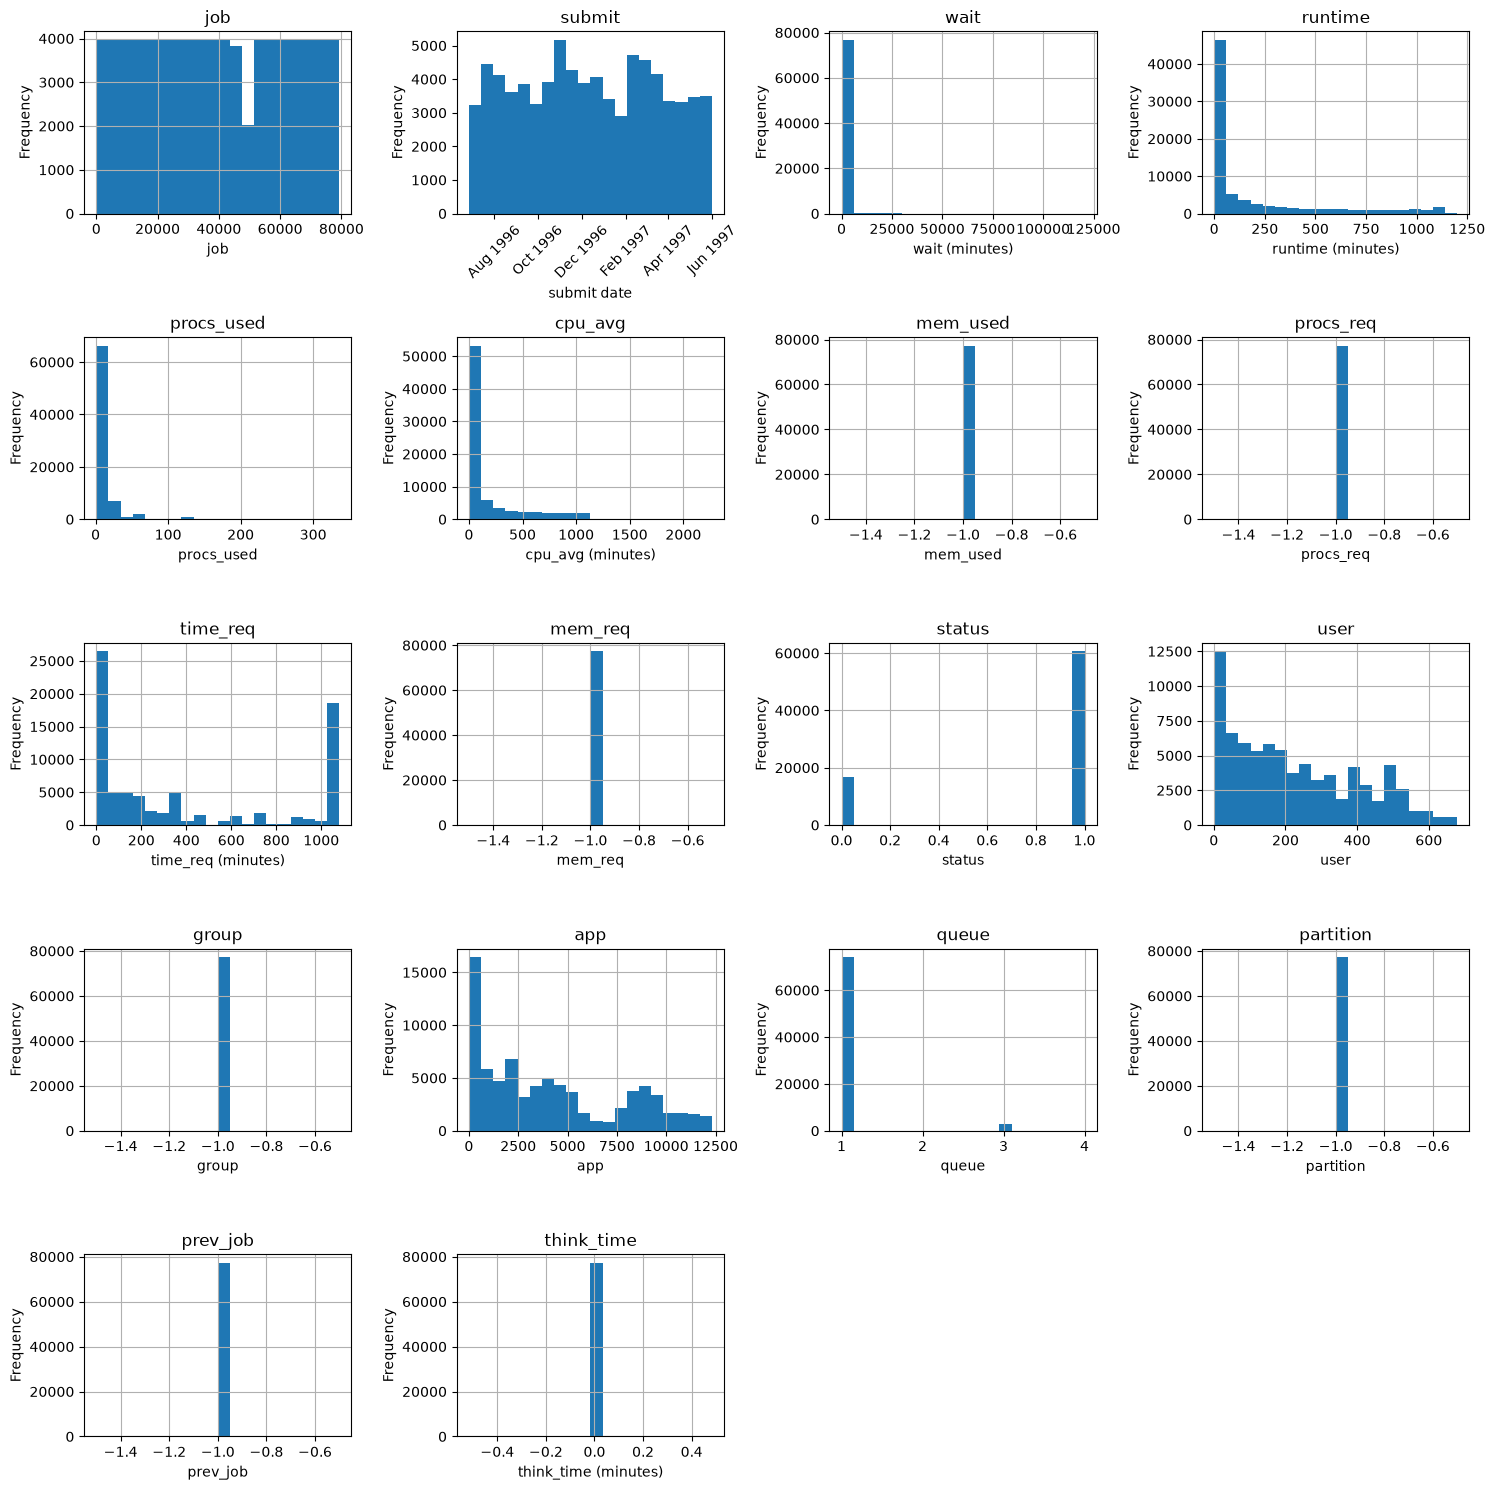

In [110]:
START = 835823160   # "UnixStartTime" in the CTC file header (for SDSC: 893466664)
TZ    = -18000      # "TimeZone" in the header, seconds from UTC (for SDSC: -28800)

time_cols = ["wait", "runtime", "cpu_avg", "time_req", "think_time"]   # seconds -> minutes

plot_df = df.copy()
present = [c for c in time_cols if c in plot_df.columns]
plot_df[present] = plot_df[present] / 60
submit_dates = pd.to_datetime(df["submit"] + START + TZ, unit="s")      # real local dates

axes = plot_df.hist(figsize=(15, 15), bins=20)

for ax in axes.flatten():
    col = ax.get_title()
    if col == "":                      # empty leftover subplots
        continue
    if col == "submit":
        ax.clear()                     # redraw this one with dates
        ax.hist(submit_dates, bins=20)
        ax.set_title("submit")
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))     # a tick every 2 months
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))     # e.g. "Oct 1996"
        ax.tick_params(axis="x", rotation=45)
        ax.set_xlabel("submit date")
    else:
        ax.set_xlabel(f"{col} (minutes)" if col in present else col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

From these plots, we notice that many columns have the value -1, meaning that the value is missing. Thus, these columns can not be used and can be dropped from the study.
The columns that will be dropped are the following:
- memory used: mem_used
- memory requested: mem_req
- think time: think_time
- previous job; prev_job
- number of processors requested: procs_req
- partition: partition

We notice that some features are skewed to the right and have different peaks. We'll explore more those features and their peaks below

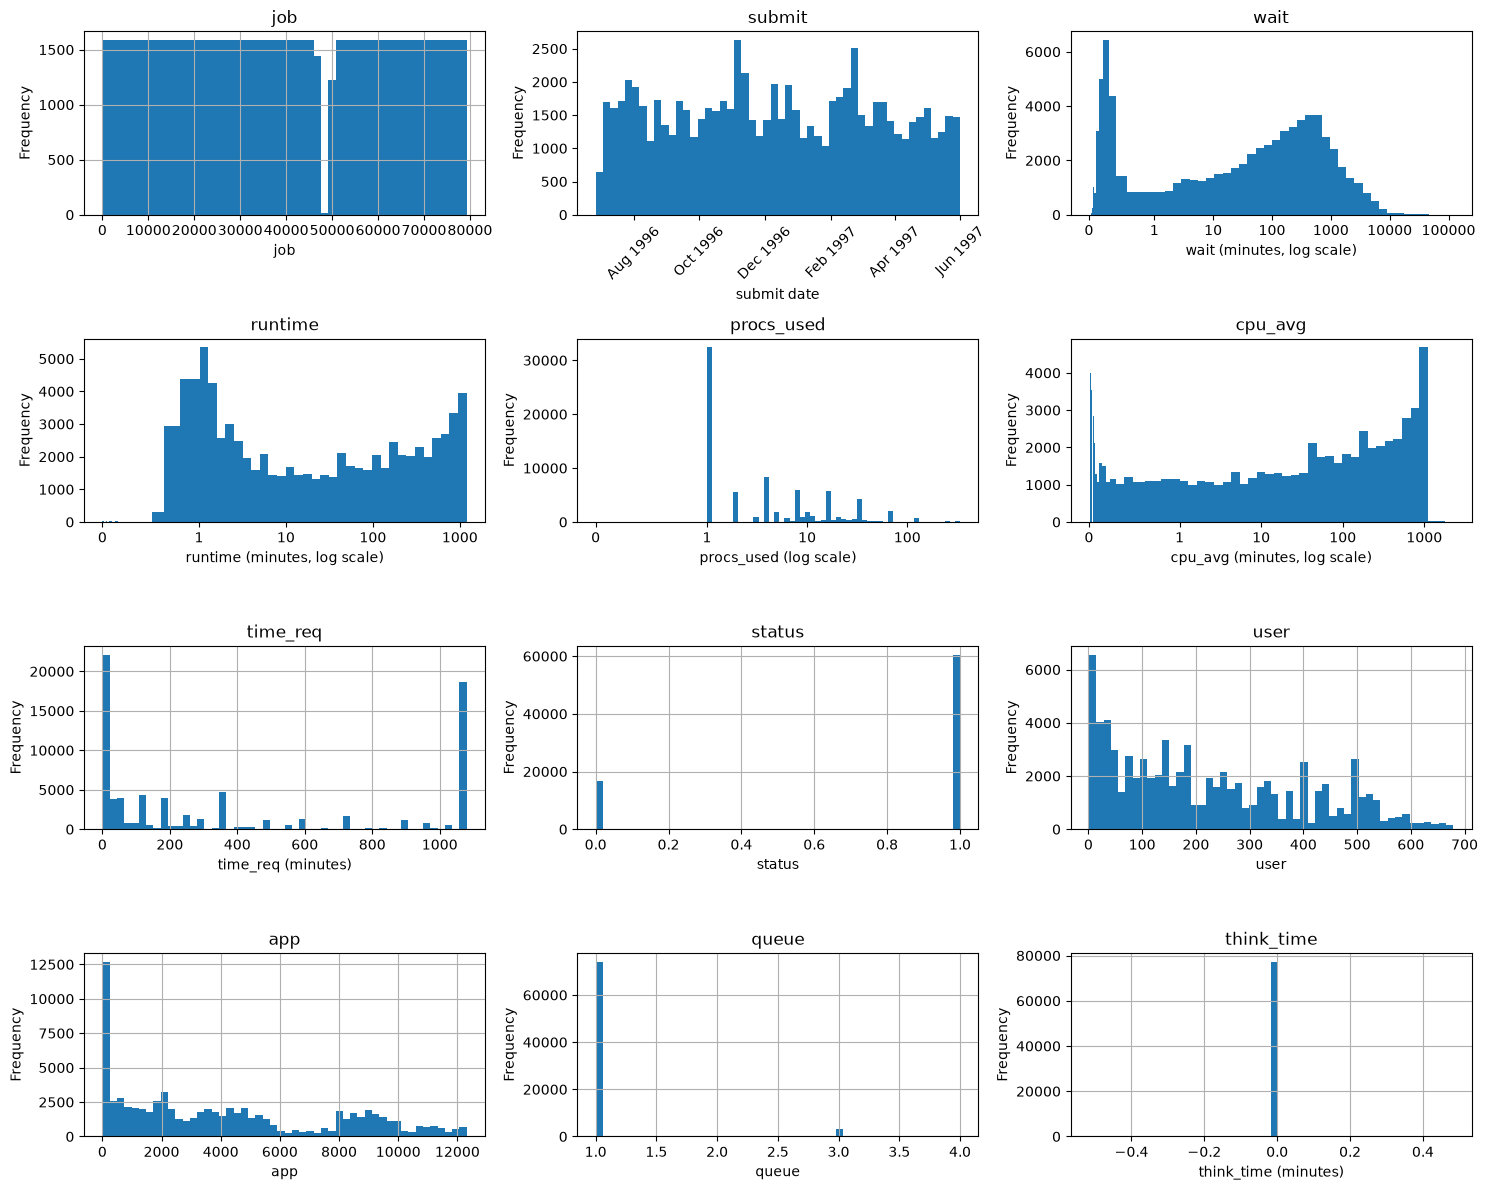

In [112]:
skewed    = ["wait", "procs_used", "runtime", "cpu_avg"]               # long right tail -> log x-axis
plot_df2 = plot_df.drop(columns=[c for c in plot_df if (plot_df[c] == -1).all()])  # drop columns that are all missing (listed above)

axes = plot_df2.hist(figsize=(15, 12), bins=50)

for ax in axes.flatten():
    col = ax.get_title()
    if col == "":
        continue
    if col == "submit":
        ax.clear()
        ax.hist(submit_dates, bins=50)
        ax.set_title("submit")
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        ax.tick_params(axis="x", rotation=45)
        ax.set_xlabel("submit date")
    elif col in skewed:
        values = plot_df2[col][plot_df2[col] >= 0]                 # ignore -1 placeholders
        ax.clear()
        smallest = min(1, values[values > 0].min())
        bins = np.concatenate([[0], np.logspace(np.log10(smallest), np.log10(values.max()), 50)])
        ax.hist(values, bins=bins)
        ax.set_xscale("symlog", linthresh=1)                     # log scale that still allows 0
        ax.xaxis.set_major_formatter(ScalarFormatter())          # 1, 10, 100 instead of 10^0, 10^1
        ax.set_title(col)
        ax.set_xlabel(f"{col} ({'minutes, ' if col in present else ''}log scale)")
    else:
        ax.set_xlabel(f"{col} (minutes)" if col in present else col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

We notice that the wait time follows a bimodal distribution:
- First peak is where jobs wait for less than a minute to start its execution
- Second peak is when jobs wait for about 100 to 1000 minutes (about 1h30min to 17 hours) to start executing. We explain this by the fact that all the processors might be busy for long periods, resulting in longer wait times

The time requested also has peaks between few minutes and 1000 minutes, and the runtime of jobs also follows, by having two peaks at 0 minutes and 1000 minutes.

These observations suggest that the hpc run two types of jobs: small running jobs that finish in few minutes and long running jobs that take the whole time limit of 17 hours

Finally, we will also be dropping id columns because they don't contribute to the study.
- job Id: job
- user id: user
- app id: app

## 2.Features Correlation

### How accurate are the users runtime estimates ?

- **Which features are redundant?** Use a correlation heatmap with Spearman correlation, which handles skewed data. Runtime and CPU time will probably be strongly correlated. → Decision: keep both, drop one, or use PCA.
- **How accurate are the users’ runtime estimates?** Plot requested time against actual runtime on a log–log scatter. Users usually overestimate a lot, which the scheduling literature documents well. A derived feature, runtime / time_req, might make a good clustering feature. → Decision: possibly engineer new features.
- **Does efficiency vary?** Plot cpu_avg / runtime, which shows how busy the processors were. Values near 0 suggest jobs that sat idle or hung.

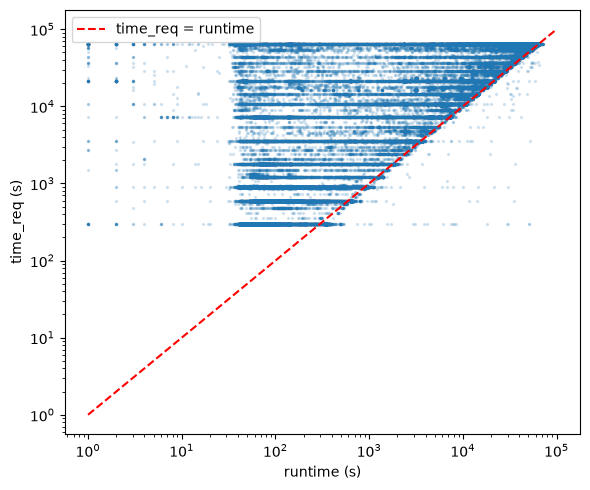

In [113]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


# keep jobs with a recorded CPU time and a positive runtime (log axes can't show 0 or -1)
d_ = df[(df["runtime"] > 0) & (df["time_req"] >= 0)]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(d_["runtime"], d_["time_req"].clip(lower=0), s=2, alpha=0.15)  # small, transparent points to show density
ax.set_xscale("log")
ax.set_yscale("log")

# reference lines: 100% busy (cpu_avg = runtime) and 10% busy
ax.plot([1, 1e5], [1, 1e5], "r--", label="time_req = runtime")
# ax.plot([1, 1e5], [0.1, 1e4], "g:", label="10% busy")

ax.set_xlabel("runtime (s)")
ax.set_ylabel("time_req (s)")
ax.legend()
plt.tight_layout()
# plt.savefig("scatter_cpu.png", dpi=150)
plt.show()

The plot shows that most users over estimate the time required for the execution of their jobs. We explain this by assuming that users request more time to make sure their job gets enough time to finish executing.

We can add this feature to the list of features used to charcterize the nature of jobs

In [270]:
# add this feature runtime / time_req
df["runtime_efficiency"] = df["runtime"] / df["time_req"] # both are in seconds

### How effecient is the CPU being used by the jobs ?

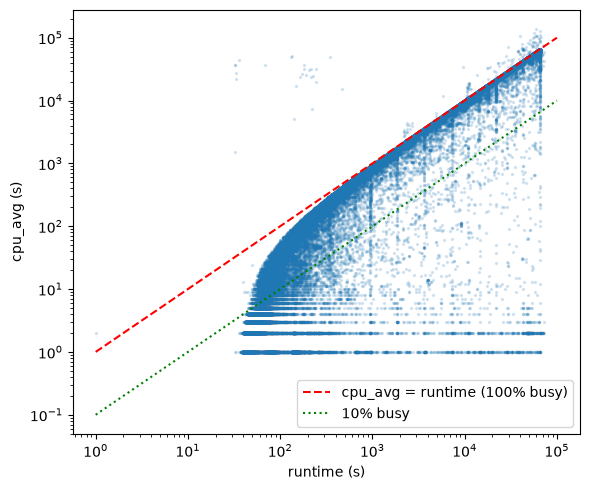

In [ ]:
# keep jobs with a recorded CPU time and a positive runtime (ignore when either column is missing (-1 rows))
d = df[(df["runtime"] > 0) & (df["cpu_avg"] >= 0)]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(d["runtime"], d["cpu_avg"].clip(lower=0.5), s=2, alpha=0.15)  
ax.set_xscale("log")
ax.set_yscale("log")

# reference lines: 100% busy (cpu_avg = runtime) and 10% busy
ax.plot([1, 1e5], [1, 1e5], "r--", label="cpu_avg = runtime (100% busy)")
ax.plot([1, 1e5], [0.1, 1e4], "g:", label="10% busy")

ax.set_xlabel("runtime (s)")
ax.set_ylabel("cpu_avg (s)")
ax.legend()
plt.tight_layout()
# plt.savefig("scatter_cpu.png", dpi=150)
plt.show()

The red line is a limit for cpu effeciency, where time spent by a single processor equals the runtime of the job.
Because the time spent by a processor can not exceed the full runtime, we assume the points above the red line as errors and should be dropped

The green line represent when the cpu is at 10% busy.

- Points under the red line: are jobs that are highly compute bound and are using the cpu to the fullest 
- Points between the green and red line: represent jobs that use the cpu for some time and the other time is spent waiting for probably I/O operations.
- Points that are below the green line represent jobs that are idle and are not using the cpu effeciently


We can also add cpu_effeciency as a feature to our clustering task

In [271]:
df["cpu_eff"] = df["cpu_avg"] / df["runtime"]

### Does the time of submission affect the wait time for a job to be started ?

In [149]:
START = 835823160   # "UnixStartTime" in the CTC header (SDSC: 893466664)
TZ    = -18000      # "TimeZone" in the header, seconds from UTC (SDSC: -28800)

w = df[df["wait"] >= 0].copy()                               # ignore -1 values (missing)
local = pd.to_datetime(w["submit"] + START + TZ, unit="s")   # machine's local time
w["hour"] = local.dt.hour
w["wait_min"] = w["wait"] / 60

# --- table: median wait per period of the day ---
periods = pd.cut(w["hour"], bins=[0, 6, 12, 18, 24], right=False,
                 labels=["night (0-6h)", "morning (6-12h)", "afternoon (12-18h)", "evening (18-24h)"])
summary = (w.groupby(periods, observed=True)["wait_min"]
             .agg(jobs="count", median_wait_min="median")
             .round(1))
print(summary)

working = w["hour"].between(6, 18)                           # 6:00-18:00
ratio = w.loc[working, "wait_min"].median() / w.loc[~working, "wait_min"].median()
print(f"\nMedian wait, working hours (6-18h): {w.loc[working, 'wait_min'].median():.1f} min")
print(f"Median wait, other hours:          {w.loc[~working, 'wait_min'].median():.1f} min")
print(f"Ratio: {ratio:.1f}x")

                     jobs  median_wait_min
hour                                      
night (0-6h)         6636              7.3
morning (6-12h)     21688             42.1
afternoon (12-18h)  30337             48.8
evening (18-24h)    18561             27.8

Median wait, working hours (6-18h): 44.5 min
Median wait, other hours:          19.6 min
Ratio: 2.3x


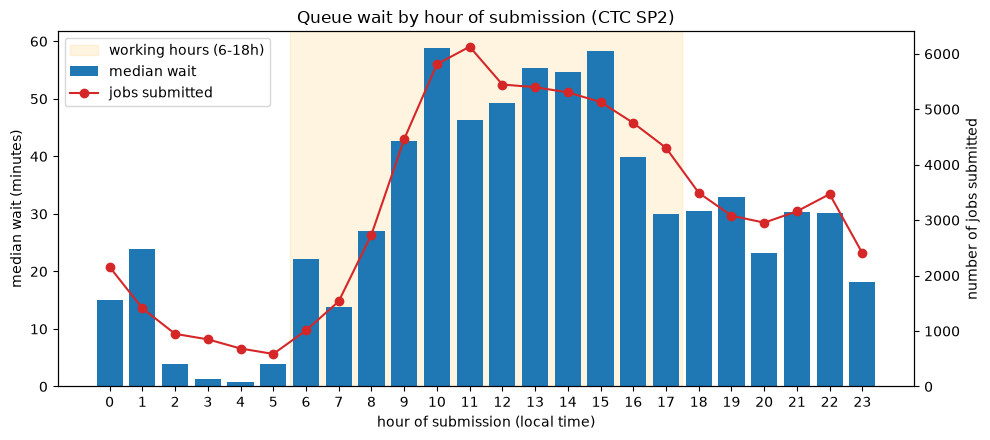

In [150]:
# median wait and number of submissions per hour of day
by_hour = w.groupby("hour").agg(median_wait=("wait_min", "median"), jobs=("job", "count"))

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.axvspan(5.5, 17.5, color="orange", alpha=0.12, label="working hours (6-18h)")
ax1.bar(by_hour.index, by_hour["median_wait"], color="tab:blue", label="median wait")
ax1.set_xlabel("hour of submission (local time)")
ax1.set_ylabel("median wait (minutes)")
ax1.set_xticks(range(24))

ax2 = ax1.twinx()                                            # second y-axis for job counts
ax2.plot(by_hour.index, by_hour["jobs"], "o-", color="tab:red", label="jobs submitted")
ax2.set_ylabel("number of jobs submitted")
ax2.set_ylim(0)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title("Queue wait by hour of submission (CTC SP2)")
plt.tight_layout()
plt.show()

We notice that during working hours the number of submitted jobs gets higher which explains why the wait time during those hours also increases.

### Does the number of running jobs affect a job's failure or completion ?

count    77222.0
mean        34.3
std         15.1
min          0.0
25%         24.0
50%         33.0
75%         44.0
max        102.0
Name: running, dtype: float64
                jobs  failure_rate  median_running
running_bin                                       
(-0.001, 16.0]  8104         0.274            12.0
(16.0, 21.0]    7722         0.220            19.0
(21.0, 26.0]    8878         0.214            24.0
(26.0, 29.0]    6410         0.207            28.0
(29.0, 33.0]    8418         0.217            31.0
(33.0, 37.0]    8480         0.207            35.0
(37.0, 41.0]    6311         0.212            40.0
(41.0, 47.0]    8157         0.200            44.0
(47.0, 54.0]    7302         0.208            51.0
(54.0, 102.0]   7440         0.195            61.0

Spearman correlation (running jobs vs failed): -0.038  (p = 2.2e-26)


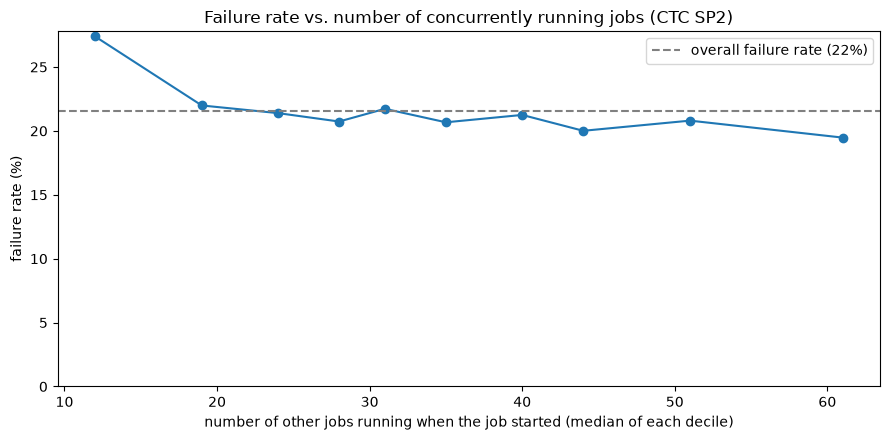

In [ ]:
r = df[(df["wait"] >= 0) & (df["runtime"] >= 0)].copy()
r["start"] = r["submit"] + r["wait"]
r["end"]   = r["start"] + r["runtime"]
r["failed"] = (r["status"] != 1).astype(int)
#TODO adjust this cell

# number of OTHER jobs running at the moment each job starts:
# (jobs that started at or before t) - (jobs that ended at or before t) - the job itself
# (a job with runtime 0 already counts as ended at t, so it is not subtracted twice)
starts = np.sort(r["start"].to_numpy())
ends   = np.sort(r["end"].to_numpy())
t = r["start"].to_numpy()
r["running"] = (np.searchsorted(starts, t, side="right")
                - np.searchsorted(ends, t, side="right")
                - (r["runtime"].to_numpy() > 0))

print(r["running"].describe().round(1))

# failure rate per group of equal size (deciles of the number of running jobs)
r["running_bin"] = pd.qcut(r["running"], q=10, duplicates="drop")
table = (r.groupby("running_bin", observed=True)
           .agg(jobs=("failed", "size"), failure_rate=("failed", "mean"),
                median_running=("running", "median")))
print(table.round(3))

from scipy.stats import spearmanr
rho, p = spearmanr(r["running"], r["failed"])
print(f"\nSpearman correlation (running jobs vs failed): {rho:.3f}  (p = {p:.1e})")

# --- plot ---
overall = r["failed"].mean()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(table["median_running"], table["failure_rate"] * 100, "o-")
ax.axhline(overall * 100, color="gray", ls="--", label=f"overall failure rate ({overall:.0%})")
ax.set_xlabel("number of other jobs running when the job started (median of each decile)")
ax.set_ylabel("failure rate (%)")
ax.set_ylim(0)
ax.set_title("Failure rate vs. number of concurrently running jobs (CTC SP2)")
ax.legend()
plt.tight_layout()
plt.show()

We notice that the number of concurrently running jobs doesn't affect the rate of failure.
We do notice that the rate of failed job when the number of concurrent job is low (lower than 20) the failure rate is at its maximum value, but we still can't find an explanation for it

### Does the number of busy processors affect a job's failure or completion ?

count    77222.0
mean       287.4
std         66.0
min          0.0
25%        272.0
50%        313.0
75%        329.0
max        591.0
Name: busy_procs, dtype: float64
                 jobs  failure_rate  median_busy
busy_bin                                        
(-0.001, 206.0]  7771         0.275        140.0
(206.0, 256.0]   7850         0.239        235.0
(256.0, 285.0]   7762         0.236        272.0
(285.0, 302.0]   7692         0.203        296.0
(302.0, 313.0]   7653         0.203        308.0
(313.0, 320.0]   8179         0.207        318.0
(320.0, 327.0]   8203         0.203        324.0
(327.0, 331.0]   7244         0.207        330.0
(331.0, 334.0]   7710         0.193        333.0
(334.0, 591.0]   7158         0.189        336.0

Spearman correlation (busy processors vs failed): -0.052  (p = 1.8e-47)


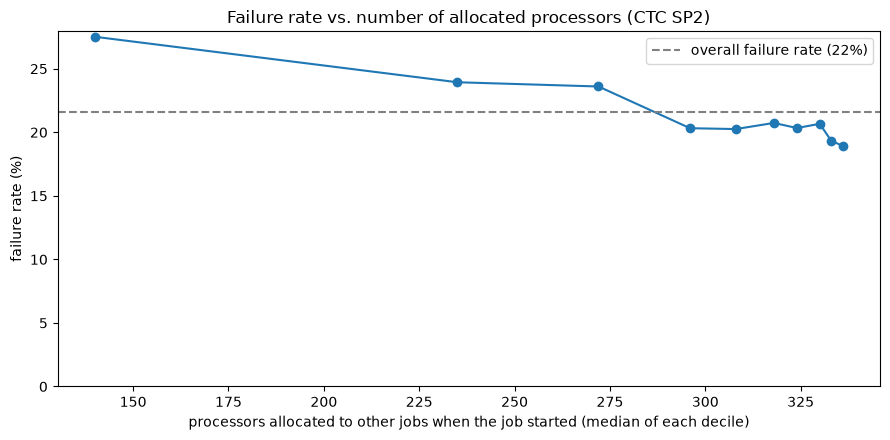

In [153]:
r = df[(df["wait"] >= 0) & (df["runtime"] >= 0) & (df["procs_used"] > 0)].copy()
r["start"] = r["submit"] + r["wait"]
r["end"]   = r["start"] + r["runtime"]
r["failed"] = (r["status"] != 1).astype(int)
#TODO correct this cell
def total_up_to(times, weights, t):
    """Sum of weights of all events with time <= t (for every t at once)."""
    order = np.argsort(times)
    cum = np.concatenate([[0], np.cumsum(weights[order])])
    return cum[np.searchsorted(times[order], t, side="right")]

procs = r["procs_used"].to_numpy()
t = r["start"].to_numpy()

# processors allocated to OTHER jobs when each job starts:
# (processors of jobs started by t) - (processors of jobs ended by t) - the job's own processors
r["busy_procs"] = (total_up_to(r["start"].to_numpy(), procs, t)
                   - total_up_to(r["end"].to_numpy(), procs, t)
                   - procs * (r["runtime"].to_numpy() > 0))

print(r["busy_procs"].describe().round(1))

# failure rate per decile of busy processors
r["busy_bin"] = pd.qcut(r["busy_procs"], q=10, duplicates="drop")
table = (r.groupby("busy_bin", observed=True)
           .agg(jobs=("failed", "size"), failure_rate=("failed", "mean"),
                median_busy=("busy_procs", "median")))
print(table.round(3))

rho, p = spearmanr(r["busy_procs"], r["failed"])
print(f"\nSpearman correlation (busy processors vs failed): {rho:.3f}  (p = {p:.1e})")

# --- plot ---
overall = r["failed"].mean()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(table["median_busy"], table["failure_rate"] * 100, "o-")
ax.axhline(overall * 100, color="gray", ls="--", label=f"overall failure rate ({overall:.0%})")
ax.set_xlabel("processors allocated to other jobs when the job started (median of each decile)")
ax.set_ylabel("failure rate (%)")
ax.set_ylim(0)
ax.set_title("Failure rate vs. number of allocated processors (CTC SP2)")
ax.legend()
plt.tight_layout()
plt.show()

Just like the previous observation a higher number of busy processors doesn't lead higher rate of failed jobs. But we do notice that the highest rate of failure is when the number of busy processors is lower than 150, without being able to explain this observation.

### Is there any period of time where jobs fail the most ?

/var/folders/m0/888lvr8511l7ykqcv7cfmmnw0000gn/T/ipykernel_79154/3073068892.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  f["weekday"]     = to_local(f["submit"]).dt.dayofweek                         # 0 = Monday


Overall failure rate: 21.6%

Highest / lowest failure rate by hour the job STOPPED:
end_hour
22    17.9
21    18.2
0     18.4
4     26.0
7     28.9
6     36.6
Name: mean, dtype: float64

Failure rate by weekday of submission (%):
Mon    19.7
Tue    22.6
Wed    24.5
Thu    20.2
Fri    22.4
Sat    21.4
Sun    20.0
Name: mean, dtype: float64


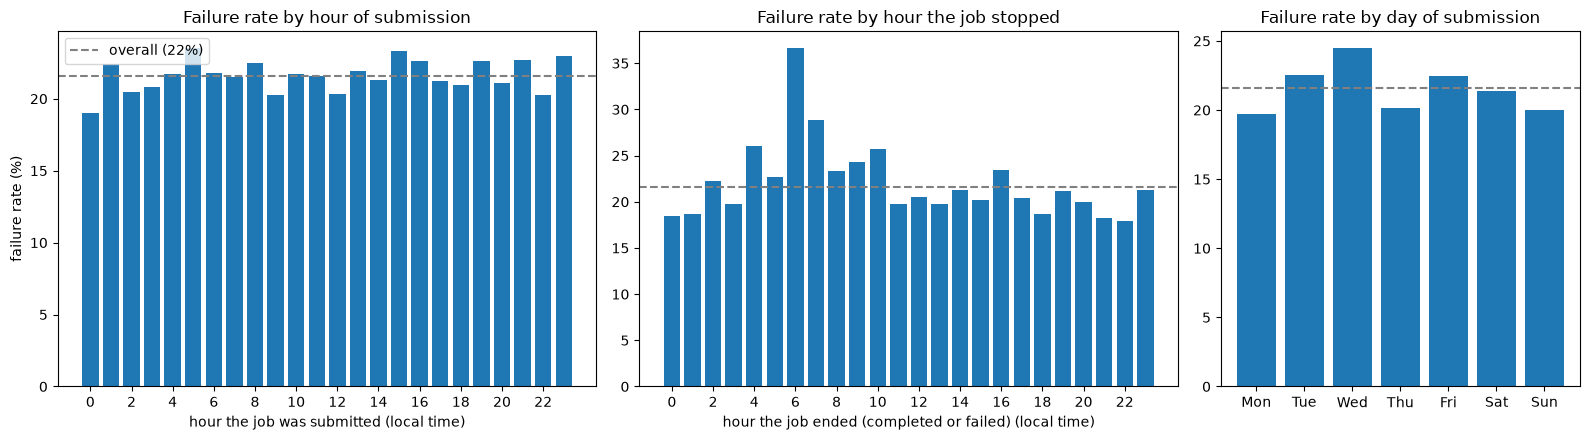

In [155]:
#TODO update the cell code

START = 835823160   # "UnixStartTime" in the CTC header (SDSC: 893466664)
TZ    = -18000      # "TimeZone" in the header, seconds from UTC (SDSC: -28800)

f = df[(df["wait"] >= 0) & (df["runtime"] >= 0)].copy()
f["failed"] = (f["status"] != 1).astype(int)
to_local = lambda s: pd.to_datetime(s + START + TZ, unit="s")
f["submit_hour"] = to_local(f["submit"]).dt.hour
f["end_hour"]    = to_local(f["submit"] + f["wait"] + f["runtime"]).dt.hour   # when the job stopped
f["weekday"]     = to_local(f["submit"]).dt.dayofweek                         # 0 = Monday

overall = f["failed"].mean()
by_submit = f.groupby("submit_hour")["failed"].agg(["mean", "size"])
by_end    = f.groupby("end_hour")["failed"].agg(["mean", "size"])
by_day    = f.groupby("weekday")["failed"].agg(["mean", "size"])
by_day.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

print(f"Overall failure rate: {overall:.1%}\n")
print("Highest / lowest failure rate by hour the job STOPPED:")
print((by_end["mean"] * 100).round(1).sort_values().iloc[[0, 1, 2, -3, -2, -1]])
print("\nFailure rate by weekday of submission (%):")
print((by_day["mean"] * 100).round(1))

# --- plot ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 3, 2]})
for ax, data, title, xlabel in [
        (axes[0], by_submit, "by hour of submission", "hour the job was submitted"),
        (axes[1], by_end,    "by hour the job stopped", "hour the job ended (completed or failed)")]:
    ax.bar(data.index, data["mean"] * 100)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel(xlabel + " (local time)")
    ax.set_title(f"Failure rate {title}")

axes[2].bar(by_day.index, by_day["mean"] * 100)
axes[2].set_title("Failure rate by day of submission")

for ax in axes:
    ax.axhline(overall * 100, color="gray", ls="--", label=f"overall ({overall:.0%})")
    ax.set_ylim(0)
axes[0].set_ylabel("failure rate (%)")
axes[0].legend()
plt.tight_layout()
plt.show()

We notice that the failure rate is not connected to any day of the week. During all days the failure rate is about 19% more or less.
By hour the job failed, we notice that there are more jobs failing during the hours of 6am to 8am during the whole year of recording, but we can't find an explanation from the logs. We hypothesize that there might be some system routine running during those hours, daily, in the HPC infrastructure. 

### Are there any redundant features ?

Pearson coeffecient assumes linear relationship between the features. For this we'll be using the spearman coeffecient for correlation

<Axes: >

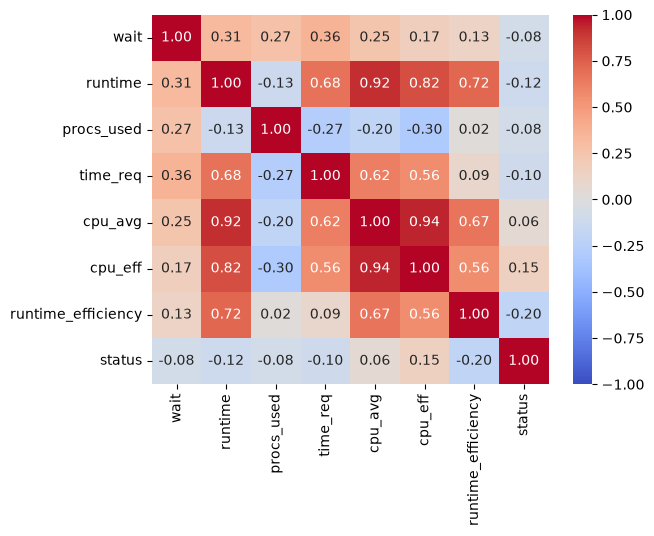

In [273]:
features = ["wait", "runtime", "procs_used", "time_req", "cpu_avg","cpu_eff", "runtime_efficiency", "status"]
corr = df[features].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)


The recommended threshold for correlation to use is usually 0.85. We notice that cpu_avg is redundant with the runtime feature with a correlation score of 0.92. Additionally, the absolute correlation score between cpu_avg and the target column status is 0.06 compared to 0.12 score between status and runtime.
So we decide to drop the column cpu_avg

In [274]:
df_features = df[features].drop("cpu_avg", axis=1)
df_features.head()

,wait,runtime,procs_used,time_req,cpu_eff,runtime_efficiency,status
0,588530,937,306,35100,0.151547,0.026695,1
1,356587,75,17,300,0.026667,0.250000,1
2,459987,35268,306,35100,0.929795,1.004786,0
3,50431,29493,64,64800,0.974638,0.455139,1
4,50766,29063,64,64800,0.969996,0.448503,1


## 3. Feature Structure

In this section we will be using PCA to project the features and see whether they have any particular structure that help clutser the jobs

In [133]:
df_features[df_features["time_req"] < 0]  # jobs that don't have a record for requested time

,wait,runtime,procs_used,time_req,cpu_eff,runtime_efficiency,status
741,2,38,4,-1,-0.026316,-38.0,0
36791,5,61,4,-1,0.032787,-61.0,1
36792,15,52,4,-1,0.019231,-52.0,1
48901,49877,91,2,-1,0.120879,-91.0,1
52802,6,56,2,-1,0.035714,-56.0,1
52803,7,50,2,-1,0.040000,-50.0,1


In [134]:
df_features[df_features["cpu_eff"] < 0] # correspond to where cpu_avg was missing

,wait,runtime,procs_used,time_req,cpu_eff,runtime_efficiency,status
15,50601,563,81,3600,-0.001776,0.156389,0
33,23356,46,10,64800,-0.021739,0.000710,0
34,22929,50,7,64800,-0.020000,0.000772,0
84,1482,206,10,64800,-0.004854,0.003179,0
91,335,164,16,14400,-0.006098,0.011389,0
...,...,...,...,...,...,...,...
76788,400,36,1,64800,-0.027778,0.000556,0
76789,400,36,1,64800,-0.027778,0.000556,0
76790,399,37,1,36000,-0.027027,0.001028,0
76791,394,37,1,36000,-0.027027,0.001028,0


In [ ]:
df_features[df_features["cpu_eff"] > 1.0] # jobs violating the effeciency possible values of 1.0 and needs to be removed

,wait,runtime,procs_used,time_req,cpu_eff,runtime_efficiency,status
5498,91668,32,8,64800,47.125000,0.000494,0
7111,133196,31738,20,64800,1.388021,0.489784,0
7256,85763,46224,16,64800,1.543203,0.713333,0
7359,47556,38075,16,64800,1.540460,0.587577,0
7461,13277,60968,4,64800,1.131774,0.940864,1
...,...,...,...,...,...,...,...
71810,29943,64838,1,64800,1.387766,1.000586,0
71811,2396,37822,1,64800,1.619904,0.583673,1
71812,29709,9577,1,64800,3.535763,0.147793,1
73588,42924,41380,1,64800,1.629145,0.638580,1


In [275]:
print(f"{len(df_features):,} jobs from original dataset")

# cleaning the features
df_features = df_features[df_features["time_req"] > 0]                      # 6 jobs with unrecorded requested time
df_features.loc[df_features["cpu_eff"] < 0, "cpu_eff"] = 0.0
df_features = df_features[df_features["cpu_eff"] <= 1.0]                    # drop impossible efficiencies (logging errors)
print(f"{len(df_features):,} jobs after cleaning")

77,222 jobs from original dataset
77,060 jobs after cleaning


Explained variance per component: [0.506 0.216 0.141 0.077 0.052 0.008]
Cumulative:                        [0.506 0.721 0.862 0.939 0.992 1.   ]


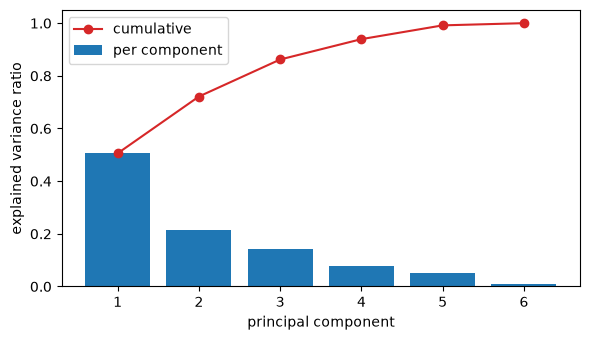

In [ ]:
# Transform and scale
log_feats = ["wait", "runtime", "procs_used", "time_req", "runtime_efficiency"]   # heavy-tailed
lin_feats = ["cpu_eff"]                                                  # already in [0, 1]
features = log_feats + lin_feats

X = pd.concat([np.log1p(df_features[log_feats]), df_features[lin_feats]], axis=1)
X_scaled = StandardScaler().fit_transform(X)

# Fit PCA
pca = PCA().fit(X_scaled)
Z = pca.transform(X_scaled)

explained = pca.explained_variance_ratio_
print("Explained variance per component:", np.round(explained, 3))
print("Cumulative:                       ", np.round(explained.cumsum(), 3))

# Plot 1: explained variance
fig, ax = plt.subplots(figsize=(6, 3.5))
pcs = np.arange(1, len(explained) + 1)
ax.bar(pcs, explained, label="per component")
ax.plot(pcs, explained.cumsum(), "o-", color="tab:red", label="cumulative")
ax.set_xticks(pcs)
ax.set_xlabel("principal component")
ax.set_ylabel("explained variance ratio")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

We conclude that 2 components keep about 72% of the variance, while 3 components explain 86% of the variance

In [142]:
# what each component means in terms of the original features
loadings = pd.DataFrame(pca.components_[:3].T, index=features, columns=["PC1", "PC2", "PC3"])
display(loadings.round(2)) if "display" in globals() else print(loadings.round(2))

                     PC1   PC2   PC3
wait                0.31  0.56 -0.30
runtime             0.56 -0.09  0.04
procs_used          0.03  0.77  0.32
time_req            0.46  0.02 -0.52
runtime_efficiency  0.39 -0.07  0.73
cpu_eff             0.47 -0.28  0.04


The first components is explained by runtime, time_req and cpu effeciency. Meaning that the first components captures job execution characteristics (runtime, time_requested) and resource usage (cpu_effeciency)

The second component captures resource allocation (procs_used) and waiting time

The third component captures runtime effeciency (runtime vs requested time)

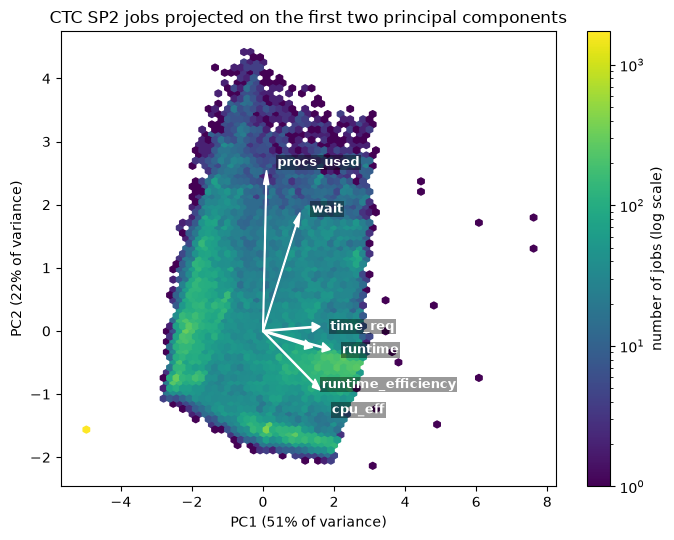

In [ ]:
# density of jobs in the PC1-PC2 plane
fig, ax = plt.subplots(figsize=(7, 5.5))
hb = ax.hexbin(Z[:, 0], Z[:, 1], gridsize=70, bins="log", cmap="viridis", mincnt=1)
fig.colorbar(hb, ax=ax, label="number of jobs (log scale)")

# arrows: direction of each original feature in this plane (biplot)
scale = 3
placed = []                                         # label positions, to avoid overlaps
for f, (x, y) in zip(features, pca.components_[:2].T):
    ax.arrow(0, 0, x * scale, y * scale, color="white", width=0.02, head_width=0.15)
    lx, ly = x * scale * 1.15 + 0.3, y * scale * 1.15
    while any(abs(lx - px) < 1.2 and abs(ly - py) < 0.3 for px, py in placed):
        ly -= 0.3                                   # move down until the label is free
    placed.append((lx, ly))
    ax.text(lx, ly, f, color="white", fontsize=9, ha="left", va="center", fontweight="bold",
            bbox=dict(facecolor="black", alpha=0.4, edgecolor="none", pad=1))

ax.set_xlabel(f"PC1 ({explained[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.0%} of variance)")
ax.set_title("CTC SP2 jobs projected on the first two principal components")
plt.tight_layout()
plt.show()


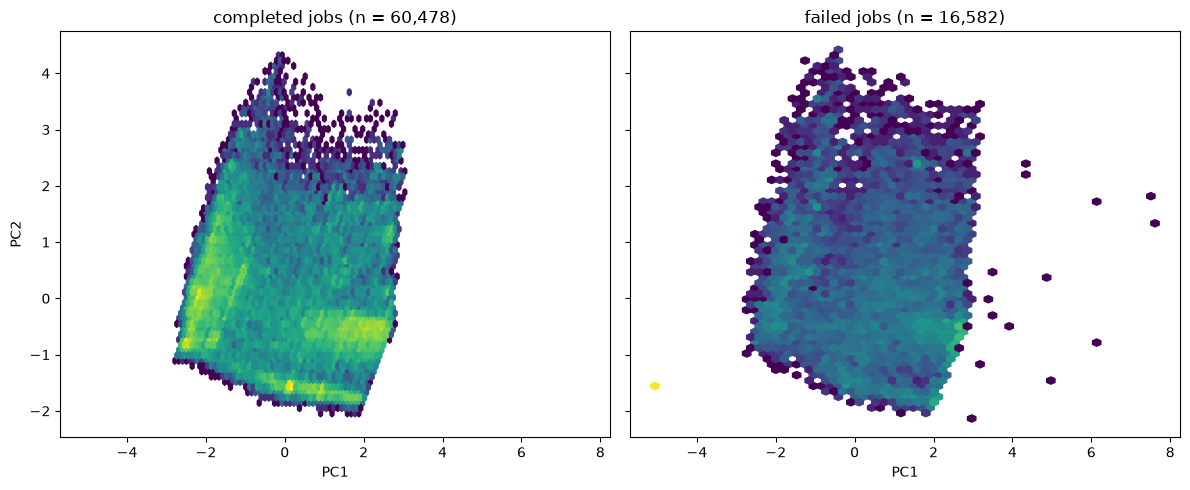

In [ ]:
# Plot 4: Projection coloured based on status of the job (failed vs completed)
failed = (df_features["status"] != 1).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, mask, name in [(axes[0], ~failed, "completed"), (axes[1], failed, "failed")]:
    ax.hexbin(Z[mask, 0], Z[mask, 1], gridsize=60, bins="log", cmap="viridis", mincnt=1)
    ax.set_title(f"{name} jobs (n = {mask.sum():,})")
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout()
plt.show()

We notice that the jobs form one mass and can hardly be separated. Additionally, we notice that some failed jobs have bigger valed of PC1 (explaining runtime, cpu_eff and time_req)compared to the completed ones.
A possible explanation for this is that, these jobs with high PC1 might be failed jobs that takes long running time and consume all the requested time then stop.

Finally, given that the data is not easily separated, we suggest to use Gaussian Mixture Models (GMM) a clustering algorithm because it handles overlapping features better than K-means that assumes there's a certain distance between the features

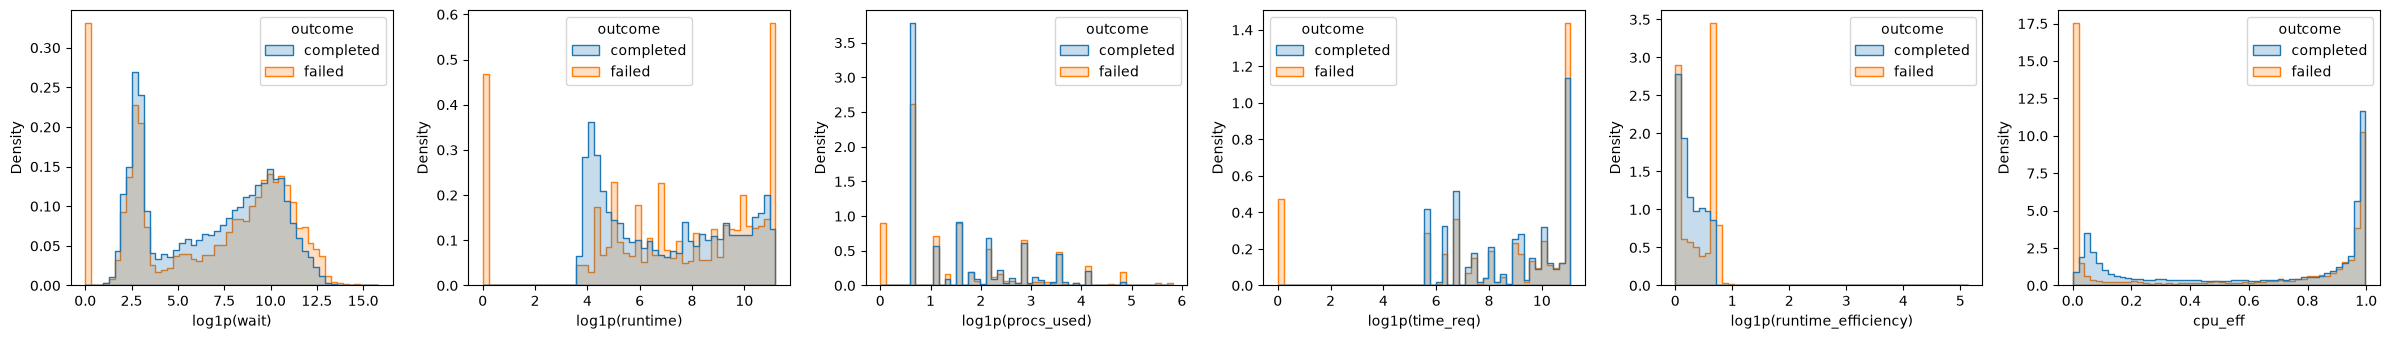

In [146]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = df_features.copy()

plot_df[log_feats] = np.log1p(plot_df[log_feats])
plot_df["outcome"] = np.where(df_features["status"] == 1, "completed", "failed")

fig, axes = plt.subplots(1, len(features), figsize=(4 * len(features), 3.5))
for ax, col in zip(axes, features):
    sns.histplot(data=plot_df, x=col, hue="outcome", bins=50,
                 stat="density", common_norm=False,   # each group sums to 1 on its own
                 element="step", ax=ax)
    ax.set_xlabel(f"log1p({col})" if col in log_feats else col)
plt.tight_layout()
plt.show()

We notice that most features overlap, meaning that no single feature separates failed jobs from completed ones.

### Does the workload in the HPC change over time ?

We are interested in this question, to decide whether we should consider time as a factor when splitting the data for the clustering task

Start: 835823160, offset timezone: -18000


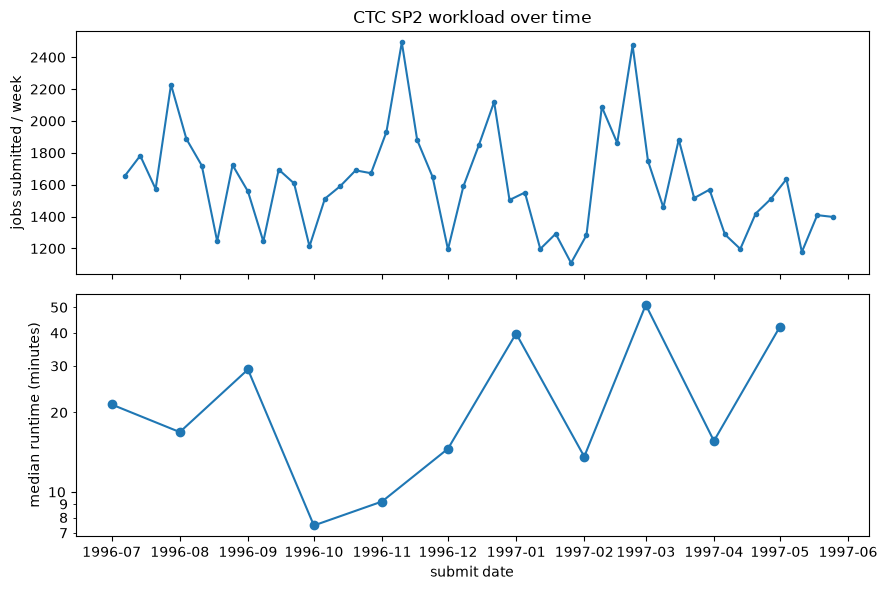

count      47.000000
mean     1614.191489
std       323.686754
min      1109.000000
25%      1403.500000
50%      1589.000000
75%      1765.500000
max      2493.000000
Name: job, dtype: float64
date
1996-07-01    21.43
1996-08-01    16.85
1996-09-01    29.08
1996-10-01     7.47
1996-11-01     9.20
1996-12-01    14.58
1997-01-01    39.78
1997-02-01    13.61
1997-03-01    51.07
1997-04-01    15.60
1997-05-01    42.18
Freq: MS, Name: runtime, dtype: float64


In [154]:
import gzip
import re
import pandas as pd
import matplotlib.pyplot as plt


FILE = "dataset-C/CTC-SP2-1996-3.1-cln.swf.gz"

# submit is in seconds since the start of the log; the header gives the real start time
opener = gzip.open if FILE.endswith(".gz") else open
with opener(FILE, "rt") as f:
    header = [line for line in f if line.startswith(";")][:60]
start = int(next(re.search(r"\d+", l).group() for l in header if "UnixStartTime" in l))
tz_offset = int(next(re.search(r"-?\d+", l).group() for l in header
                     if l.startswith("; TimeZone:")))      # seconds from UTC, e.g. -18000

print(f"Start: {start}, offset timezone: {tz_offset}")

df["date"] = pd.to_datetime(df["submit"] + start + tz_offset, unit="s")  # machine's local time
df = df.set_index("date")

# 1) number of jobs submitted per week
weekly = df["job"].resample("W").count()

# 2) median runtime per month (only jobs with a recorded runtime)
monthly = df.loc[df["runtime"] >= 0, "runtime"].resample("MS").median() / 60  # minutes

# keep only periods the log covers completely (it may start or end mid-week / mid-month)
first, last = df.index.min(), df.index.max()
weekly = weekly[(weekly.index - pd.Timedelta(days=6) >= first.normalize())
                & (weekly.index <= last.normalize())]        # weekly labels = the week's last day
monthly = monthly[(monthly.index >= first.normalize())
                  & (monthly.index + pd.offsets.MonthEnd(0) <= last.normalize())]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax1.plot(weekly.index, weekly.values, marker=".")
ax1.set_ylabel("jobs submitted / week")
ax1.set_title("CTC SP2 workload over time")

ax2.plot(monthly.index, monthly.values, marker="o")
ax2.set_yscale("log")                      # medians differ by several times between months
ax2.yaxis.set_major_formatter(plt.ScalarFormatter())   # plain numbers instead of 10^x
ax2.yaxis.set_minor_formatter(plt.ScalarFormatter())
ax2.set_ylabel("median runtime (minutes)")
ax2.set_xlabel("submit date")

plt.tight_layout()
plt.savefig("time_trends.png", dpi=150)
plt.show()

print(weekly.describe())
print(monthly.round(2))

- **Jobs submitted per week**: We notice that the number of jobs submitted per week follows a stable trend over the whole period of recording the logs, with few busy weeks in november-december and feb-march.
- **Jobs runtime**: We notice that overall, the median runtime started to follow an increasing trend after the tenth month of 1996 where it started at 7 minutes to reach 40 minutes job runtime in january 1997, then it went down a bit in february to rise again to 50mins in March.

These observations suggest that the split of the data should be time based. Meaning that training on past data should make the model able to predict test data from future dates.

## Features Preprocessing

- First, we'll split the data based on submission week
- Many features are rightly skewed, for those we'll apply the ln(x+1) function.
- Also, because the features are in different scales, we'll standardize them

### Splitting the data into Training + Testing sets

In [ ]:
cols = ["job","submit","wait","runtime","procs_used","cpu_avg","mem_used",
        "procs_req","time_req","mem_req","status","user","group","app",
        "queue","partition","prev_job","think_time"]

df = pd.read_csv(DATASET_PATH, sep=r"\s+", comment=";", names=cols)
df_feat_joined = df_features.join(df[["submit"]])

# sort values by submission time
# assumes df is already cleaned and contains the "submit" column
df_feat_joined = df_feat_joined.sort_values("submit")

t_val, t_test = df_feat_joined["submit"].quantile([0.70, 0.85])     # cut points: 70% / 15% / 15% of jobs

train = df_feat_joined[df_feat_joined["submit"] <  t_val]
val   = df_feat_joined[(df_feat_joined["submit"] >= t_val) & (df_feat_joined["submit"] < t_test)]
test  = df_feat_joined[df_feat_joined["submit"] >= t_test]

START, TZ = 835823160, -18000                            # from the CTC header
for name, part in [("train", train), ("val", val), ("test", test)]:
    dates = pd.to_datetime(part["submit"] + START + TZ, unit="s")
    print(f"{name:5s} {len(part):6,d} jobs  {dates.min():%Y-%m-%d} -> {dates.max():%Y-%m-%d}")

X_train, y_train = train.drop(["status", "submit"], axis=1), train[["status"]]
X_val_prep, y_val =  val.drop(["status", "submit"], axis=1), val[["status"]]
X_test, y_test =  test.drop(["status", "submit"], axis=1), test[["status"]]

train 53,942 jobs  1996-06-26 -> 1997-02-16
val   11,559 jobs  1997-02-16 -> 1997-04-03
test  11,559 jobs  1997-04-03 -> 1997-05-31


In [277]:
# Applying the log to skwed features
log_feats = ["wait", "runtime", "procs_used", "time_req", "runtime_efficiency"]   # heavy-tailed
lin_feats = ["cpu_eff"]                                                  # already in [0, 1]
features = log_feats + lin_feats

X_train = pd.concat([np.log1p(X_train[log_feats]), X_train[lin_feats]], axis=1)
X_val = pd.concat([np.log1p(X_val[log_feats]), X_val[lin_feats]], axis=1)
X_test = pd.concat([np.log1p(X_test[log_feats]), X_test[lin_feats]], axis=1)

In [278]:
# bringing all the features to the same scale
scaler = StandardScaler()
fit_scaler = scaler.fit(X_train)

X_train_prep = fit_scaler.transform(X_train)
X_val_prep = fit_scaler.transform(X_val)
X_test_prep = fit_scaler.transform(X_test)


## Training GMM Model

GMM covariance types explained:
- **Full** : Each component has its own full covariance matrix. It allows each component to have a unique shape, orientation and size in all dimensions. Provides the most flexibility but also increases computational cost.
- **Tied** : All components share a single common full covariance matrix. Provide all clusters to have the same shape and orientation making it more restrictive. Useful when components are expected to be similar in spread.
- **Diagonal** : Each component has its own diagonal covariance matrix and allows each component to have different variances along each dimension but assumes no correlation between dimensions. Computationally efficient and useful for high-dimensional data.
- **Spherical** : Each component has a single variance value across all dimensions. Assumes that all clusters are spherical and identical in all directions. The simplest model but often too restrictive for real-world data.

### Model Selection

36 models fitted in 136 s


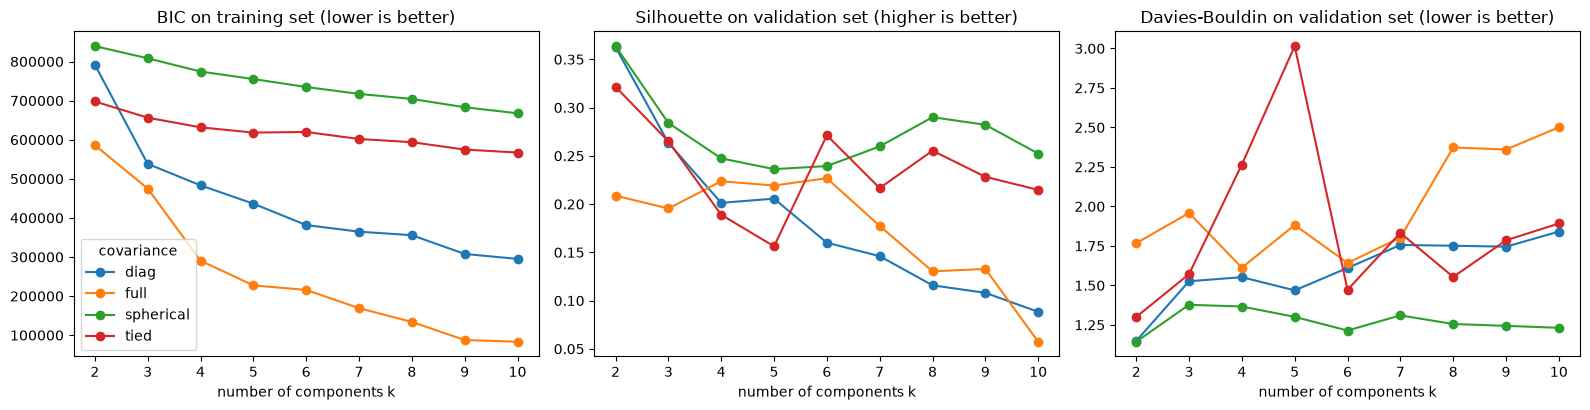

In [ ]:
assert len(val) == len(X_val_prep), "val must contain the same jobs as X_val, in the same order"
outcome = np.where(val["status"].to_numpy() == 1, "completed", "failed")

rng = np.random.default_rng(0)
sil_idx = rng.choice(len(X_val_prep), size=min(5000, len(X_val_prep)), replace=False)  # silhouette is O(n^2)

# %% Model selection: covariance type x number of components
# BIC is computed on the training set, silhouette and Davies-Bouldin on the validation set.
covariance_types = ["full", "tied", "diag", "spherical"]
k_values = range(2, 11)

rows = []
t0 = time.time()
for cov in covariance_types:
    for k in k_values:
        gmm = GaussianMixture(n_components=k, covariance_type=cov, n_init=10, random_state=0).fit(X_train_prep)
        pred = gmm.predict(X_val_prep)
        rows.append({
            "covariance": cov, "k": k,
            "BIC_train": gmm.bic(X_train_prep),
            "silhouette_val": silhouette_score(np.asarray(X_val_prep)[sil_idx], pred[sil_idx]),
            "davies_bouldin_val": davies_bouldin_score(X_val_prep, pred),
            "converged": gmm.converged_,
        })
selection = pd.DataFrame(rows)
print(f"{len(rows)} models fitted in {time.time() - t0:.0f} s")

# %% Plot the selection metrics
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
metrics = [("BIC_train", "BIC on training set (lower is better)"),
           ("silhouette_val", "Silhouette on validation set (higher is better)"),
           ("davies_bouldin_val", "Davies-Bouldin on validation set (lower is better)")]
for ax, (col, title) in zip(axes, metrics):
    for cov, part in selection.groupby("covariance"):
        ax.plot(part["k"], part[col], "o-", label=cov)
    ax.set_title(title)
    ax.set_xlabel("number of components k")
    ax.set_xticks(list(k_values))
axes[0].legend(title="covariance")
plt.tight_layout()
plt.show()

We notice that in the training, the lowest BIC is achieved by the gmm model using a full covariance type.
Correspondingly, the highest validation silhouette score and the lowest Davies-Bouldin score are achived at k = 4.
Thus we choose the number of clusters to be 4

In [285]:
# Final model choice
BEST_COV = "full"
BEST_K = 6

final_gmm = GaussianMixture(n_components=BEST_K, covariance_type=BEST_COV,
                            n_init=10, random_state=0).fit(X_train_prep)
clusters = final_gmm.predict(X_val_prep)

ari = adjusted_rand_score(outcome, clusters)
nmi = normalized_mutual_info_score(outcome, clusters)
print(f"Final model: k = {BEST_K}, covariance = {BEST_COV}")
print(f"Agreement with job outcome (external check): ARI = {ari:.3f}, NMI = {nmi:.3f}")


Final model: k = 6, covariance = full
Agreement with job outcome (external check): ARI = 0.025, NMI = 0.042


### Cluster profiles

In [286]:
# cluster features and according failure rates
prof_df = val.assign(cluster=clusters, failed=(outcome == "failed"))
if "req_used" not in prof_df:
    prof_df["req_used"] = prof_df["runtime"] / prof_df["time_req"]

profile = prof_df.groupby("cluster").agg(
    jobs=("failed", "size"),
    failure_rate=("failed", "mean"),
    median_runtime_min=("runtime", lambda s: s.median() / 60),
    median_wait_min=("wait", lambda s: s.median() / 60),
    median_procs=("procs_used", "median"),
    median_time_req_min=("time_req", lambda s: s.median() / 60),
    median_req_used=("req_used", "median"),
)
if "cpu_eff" in prof_df:
    profile["median_cpu_eff"] = prof_df.groupby("cluster")["cpu_eff"].median()
profile["share_of_jobs"] = profile["jobs"] / profile["jobs"].sum()
profile = profile.sort_values("failure_rate")
print(f"Overall failure rate: {(outcome == 'failed').mean():.1%}")
profile.round(2)

Overall failure rate: 19.0%


,jobs,failure_rate,median_runtime_min,median_wait_min,median_procs,median_time_req_min,median_req_used,median_cpu_eff,share_of_jobs
cluster,,,,,,,,,
3,1895,0.04,1.10,6.57,2.0,10.0,0.14,0.07,0.16
2,2025,0.13,13.55,129.30,13.0,120.0,0.15,0.77,0.18
1,3488,0.14,393.49,236.08,1.0,1080.0,0.56,0.99,0.30
0,1618,0.25,1.43,164.01,2.0,360.0,0.01,0.05,0.14
4,2133,0.37,268.05,482.88,16.0,360.0,0.80,0.91,0.18
5,400,0.46,15.72,0.28,5.0,20.0,0.75,0.76,0.03


## Training K-means Model

9 models fitted in 3 s
 k  inertia_train  silhouette_val  davies_bouldin_val
 2     204428.013           0.364               1.148
 3     171245.941           0.343               1.192
 4     150133.889           0.307               1.319
 5     131984.779           0.310               1.235
 6     116890.805           0.303               1.208
 7     106140.403           0.317               1.124
 8      97641.879           0.313               1.076
 9      91157.390           0.308               1.075
10      85054.799           0.282               1.204


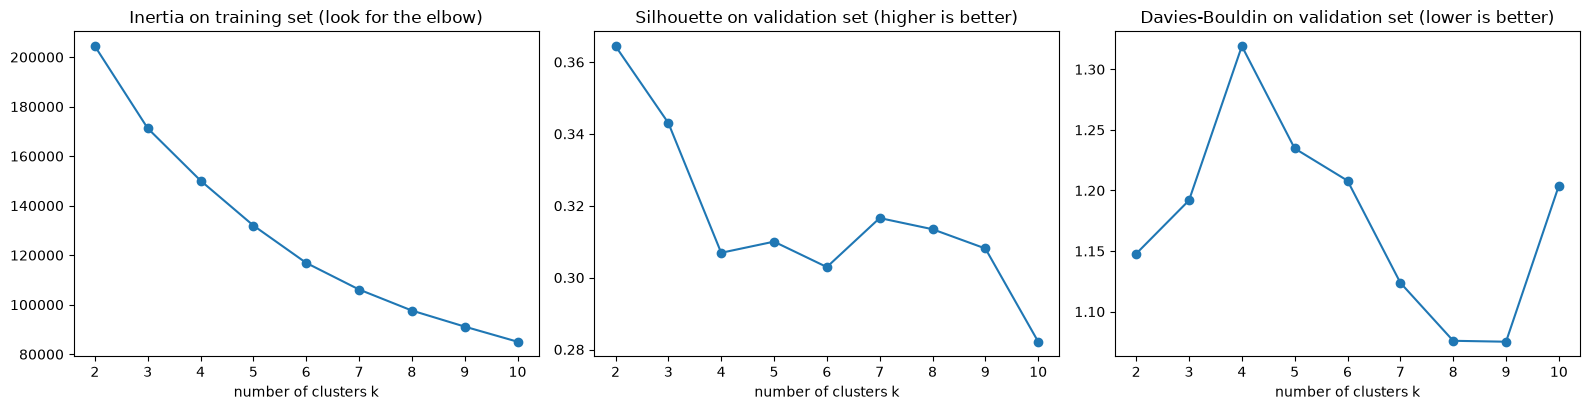

Highest validation silhouette: k = 2 (0.364)


In [293]:
# %% [markdown]
# # K-means clustering: model selection, final model, comparison with job outcome and with the GMM
# Needs the same variables as the GMM cells: X_train_prep, X_val_prep (scaled), val (original rows of the
# validation jobs, same order as X_val_prep). If the GMM cells were run before, the GMM clusters
# (`clusters`, `BEST_K`) are used for the comparison at the end.

# %% Imports
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)

assert len(val) == len(X_val_prep), "val must contain the same jobs as X_val, in the same order"
outcome = np.where(val["status"].to_numpy() == 1, "completed", "failed")

rng = np.random.default_rng(0)
sil_idx = rng.choice(len(X_val_prep), size=min(5000, len(X_val_prep)), replace=False)  # silhouette is O(n^2)

# %% Model selection over k
# Inertia (within-cluster sum of squares) on the training set -> elbow method.
# Silhouette and Davies-Bouldin on the validation set.
k_values = range(2, 11)
rows = []
t0 = time.time()
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_train_prep)
    pred = km.predict(X_val_prep)
    rows.append({
        "k": k,
        "inertia_train": km.inertia_,
        "silhouette_val": silhouette_score(np.asarray(X_val_prep)[sil_idx], pred[sil_idx]),
        "davies_bouldin_val": davies_bouldin_score(X_val_prep, pred),
    })
km_selection = pd.DataFrame(rows)
print(f"{len(rows)} models fitted in {time.time() - t0:.0f} s")
print(km_selection.round(3).to_string(index=False))

# %% Plot the selection metrics
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
metrics = [("inertia_train", "Inertia on training set (look for the elbow)"),
           ("silhouette_val", "Silhouette on validation set (higher is better)"),
           ("davies_bouldin_val", "Davies-Bouldin on validation set (lower is better)")]
for ax, (col, title) in zip(axes, metrics):
    ax.plot(km_selection["k"], km_selection[col], "o-")
    ax.set_title(title)
    ax.set_xlabel("number of clusters k")
    ax.set_xticks(list(k_values))
plt.tight_layout()
plt.show()

best_km = km_selection.loc[km_selection["silhouette_val"].idxmax()]
print(f"Highest validation silhouette: k = {int(best_km['k'])} ({best_km['silhouette_val']:.3f})")

Final K-means: k = 6
Agreement with job outcome (external check): ARI = 0.004, NMI = 0.020
Overall failure rate: 19.0%


/Users/admin/Documents/Luxembourg/hpc-courses/ML/Assignement 1/.ul/lib/python3.11/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


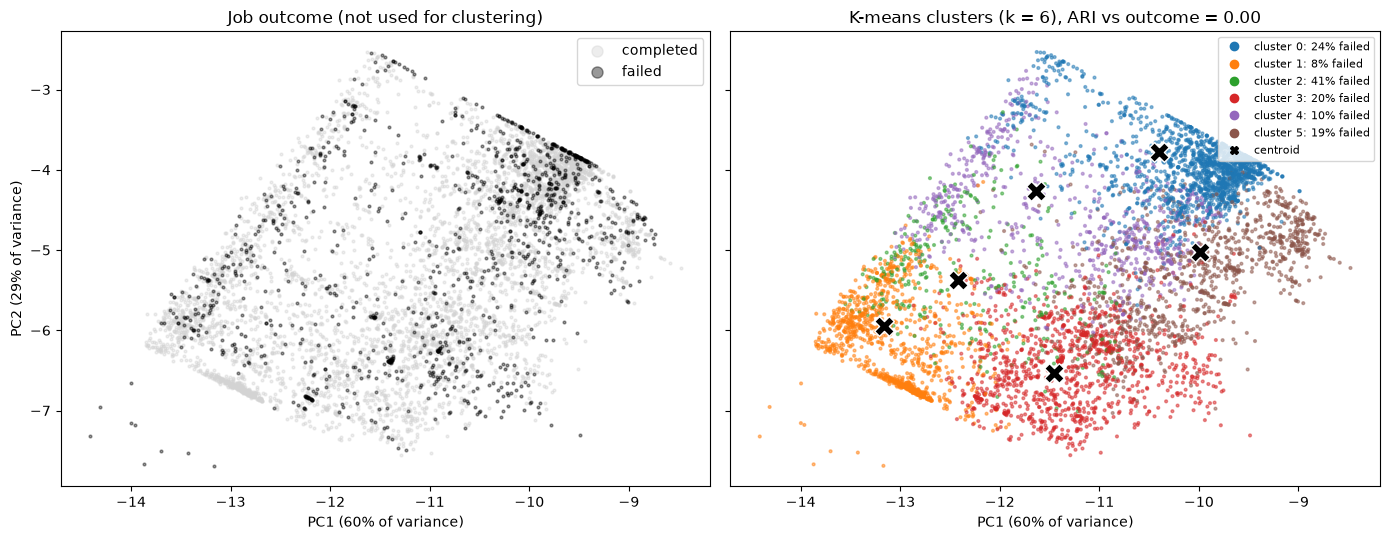

Agreement between K-means (k = 6) and GMM (k = 6) on the validation set:
  ARI = 0.429, NMI = 0.483
  Silhouette on validation: GMM = 0.227, K-means = 0.303

Rows = GMM clusters, columns = K-means clusters (number of jobs):
K-means     0     1    2     3    4     5
GMM                                      
0           0   266    0  1144  196    12
1        2649     0   64     0  775     0
2          61   345   85   551  397   586
3           0  1463    9   423    0     0
4         512    13  279    23    6  1300
5          39    46  278     0   21    16


In [295]:

# %% Final K-means model
# Default: the same k as the GMM, so both models are compared on equal terms.
# (Silhouette tends to favour k = 2 here: the coarse short-vs-long split.)
# Without the GMM cells, the k with the highest validation silhouette is used.
KM_K = int(BEST_K) if "BEST_K" in globals() else int(best_km["k"])

final_km = KMeans(n_clusters=KM_K, n_init=20, random_state=0).fit(X_train_prep)
km_clusters = final_km.predict(X_val_prep)

km_ari = adjusted_rand_score(outcome, km_clusters)
km_nmi = normalized_mutual_info_score(outcome, km_clusters)
print(f"Final K-means: k = {KM_K}")
print(f"Agreement with job outcome (external check): ARI = {km_ari:.3f}, NMI = {km_nmi:.3f}")

# %% Cluster profiles (original units) with failure rate per cluster
km_prof_df = val.assign(cluster=km_clusters, failed=(outcome == "failed"))
if "req_used" not in km_prof_df:
    km_prof_df["req_used"] = km_prof_df["runtime"] / km_prof_df["time_req"]

km_profile = km_prof_df.groupby("cluster").agg(
    jobs=("failed", "size"),
    failure_rate=("failed", "mean"),
    median_runtime_min=("runtime", lambda s: s.median() / 60),
    median_wait_min=("wait", lambda s: s.median() / 60),
    median_procs=("procs_used", "median"),
    median_time_req_min=("time_req", lambda s: s.median() / 60),
    median_req_used=("req_used", "median"),
)
if "cpu_eff" in km_prof_df:
    km_profile["median_cpu_eff"] = km_prof_df.groupby("cluster")["cpu_eff"].median()
km_profile["share_of_jobs"] = km_profile["jobs"] / km_profile["jobs"].sum()
km_profile = km_profile.sort_values("failure_rate")
print(f"Overall failure rate: {(outcome == 'failed').mean():.1%}")
km_profile.round(2)

# %% Figure: job outcome vs K-means clusters, in the same PCA plane as the GMM figure
pca = PCA(n_components=2).fit(X_train)
Z = pca.transform(X_val_prep)
idx = rng.choice(len(Z), size=min(6000, len(Z)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for label, color in [("completed", "lightgray"), ("failed", "black")]:
    m = outcome[idx] == label
    axes[0].scatter(Z[idx][m, 0], Z[idx][m, 1], s=4, alpha=0.4, c=color, label=label)
axes[0].set_title("Job outcome (not used for clustering)")
axes[0].legend(markerscale=4)

axes[1].scatter(Z[idx, 0], Z[idx, 1], c=km_clusters[idx], cmap="tab10",
                vmin=-0.5, vmax=9.5, s=4, alpha=0.5)
centers = pca.transform(pd.DataFrame(final_km.cluster_centers_, columns=X_train.columns))  # centroids in PCA plane
axes[1].scatter(centers[:, 0], centers[:, 1], marker="X", s=200, c="black", edgecolors="white")
axes[1].set_title(f"K-means clusters (k = {KM_K}), ARI vs outcome = {km_ari:.2f}")
handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(c),
                      label=f"cluster {c}: {km_profile.loc[c, 'failure_rate']:.0%} failed")
           for c in sorted(np.unique(km_clusters))]
handles.append(plt.Line2D([], [], marker="X", ls="", color="black", label="centroid"))
axes[1].legend(handles=handles, fontsize=8, loc="upper right")

for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.tight_layout()
plt.show()

# %% Comparison with the GMM (only if the GMM cells were run)
if "clusters" in globals() and len(clusters) == len(km_clusters):
    print(f"Agreement between K-means (k = {KM_K}) and GMM (k = {BEST_K}) on the validation set:")
    print(f"  ARI = {adjusted_rand_score(clusters, km_clusters):.3f}, "
          f"NMI = {normalized_mutual_info_score(clusters, km_clusters):.3f}")
    gmm_sil = silhouette_score(np.asarray(X_val_prep)[sil_idx], clusters[sil_idx])
    km_sil = silhouette_score(np.asarray(X_val_prep)[sil_idx], km_clusters[sil_idx])
    print(f"  Silhouette on validation: GMM = {gmm_sil:.3f}, K-means = {km_sil:.3f}")
    print("\nRows = GMM clusters, columns = K-means clusters (number of jobs):")
    display(pd.crosstab(pd.Series(clusters, name="GMM"), pd.Series(km_clusters, name="K-means"))) \
        if "display" in globals() else \
        print(pd.crosstab(pd.Series(clusters, name="GMM"), pd.Series(km_clusters, name="K-means")))

Highest validation silhouette: k = 2 (0.364)
Final K-means: k = 6
Agreement with job outcome (external check): ARI = 0.004, NMI = 0.020
Overall failure rate: 19.0%


/Users/admin/Documents/Luxembourg/hpc-courses/ML/Assignement 1/.ul/lib/python3.11/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


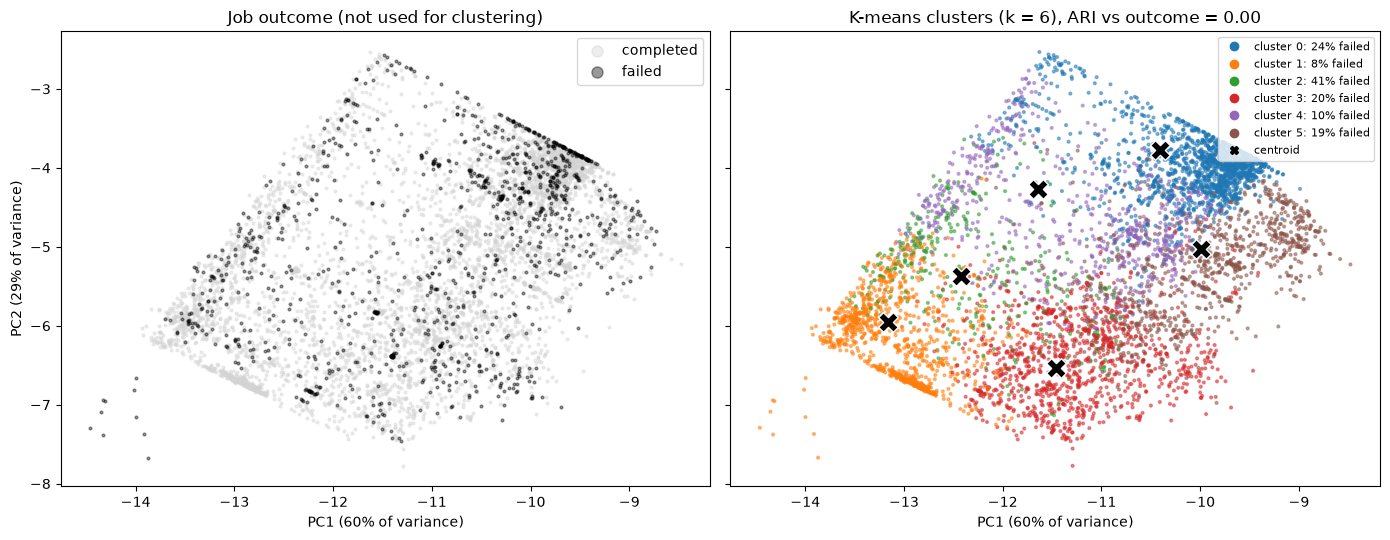

Agreement between K-means (k = 6) and GMM (k = 6) on the validation set:
  ARI = 0.429, NMI = 0.483
  Silhouette on validation: GMM = 0.227, K-means = 0.303

Rows = GMM clusters, columns = K-means clusters (number of jobs):
K-means     0     1    2     3    4     5
GMM                                      
0           0   266    0  1144  196    12
1        2649     0   64     0  775     0
2          61   345   85   551  397   586
3           0  1463    9   423    0     0
4         512    13  279    23    6  1300
5          39    46  278     0   21    16


In [297]:

best_km = km_selection.loc[km_selection["silhouette_val"].idxmax()]
print(f"Highest validation silhouette: k = {int(best_km['k'])} ({best_km['silhouette_val']:.3f})")

# %% Final K-means model
# Default: the same k as the GMM, so both models are compared on equal terms.
# (Silhouette tends to favour k = 2 here: the coarse short-vs-long split.)
# Without the GMM cells, the k with the highest validation silhouette is used.
KM_K = int(BEST_K) if "BEST_K" in globals() else int(best_km["k"])

final_km = KMeans(n_clusters=KM_K, n_init=20, random_state=0).fit(X_train_prep)
km_clusters = final_km.predict(X_val_prep)

km_ari = adjusted_rand_score(outcome, km_clusters)
km_nmi = normalized_mutual_info_score(outcome, km_clusters)
print(f"Final K-means: k = {KM_K}")
print(f"Agreement with job outcome (external check): ARI = {km_ari:.3f}, NMI = {km_nmi:.3f}")

# %% Cluster profiles (original units) with failure rate per cluster
km_prof_df = val.assign(cluster=km_clusters, failed=(outcome == "failed"))
if "req_used" not in km_prof_df:
    km_prof_df["req_used"] = km_prof_df["runtime"] / km_prof_df["time_req"]

km_profile = km_prof_df.groupby("cluster").agg(
    jobs=("failed", "size"),
    failure_rate=("failed", "mean"),
    median_runtime_min=("runtime", lambda s: s.median() / 60),
    median_wait_min=("wait", lambda s: s.median() / 60),
    median_procs=("procs_used", "median"),
    median_time_req_min=("time_req", lambda s: s.median() / 60),
    median_req_used=("req_used", "median"),
)
if "cpu_eff" in km_prof_df:
    km_profile["median_cpu_eff"] = km_prof_df.groupby("cluster")["cpu_eff"].median()
km_profile["share_of_jobs"] = km_profile["jobs"] / km_profile["jobs"].sum()
km_profile = km_profile.sort_values("failure_rate")
print(f"Overall failure rate: {(outcome == 'failed').mean():.1%}")
km_profile.round(2)

# %% Figure: job outcome vs K-means clusters, in the same PCA plane as the GMM figure
pca = PCA(n_components=2).fit(X_train)
Z = pca.transform(X_val_prep)
idx = rng.choice(len(Z), size=min(6000, len(Z)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for label, color in [("completed", "lightgray"), ("failed", "black")]:
    m = outcome[idx] == label
    axes[0].scatter(Z[idx][m, 0], Z[idx][m, 1], s=4, alpha=0.4, c=color, label=label)
axes[0].set_title("Job outcome (not used for clustering)")
axes[0].legend(markerscale=4)

axes[1].scatter(Z[idx, 0], Z[idx, 1], c=km_clusters[idx], cmap="tab10",
                vmin=-0.5, vmax=9.5, s=4, alpha=0.5)
centers = pca.transform(pd.DataFrame(final_km.cluster_centers_, columns=X_train.columns))  # centroids in PCA plane
axes[1].scatter(centers[:, 0], centers[:, 1], marker="X", s=200, c="black", edgecolors="white")
axes[1].set_title(f"K-means clusters (k = {KM_K}), ARI vs outcome = {km_ari:.2f}")
handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(c),
                      label=f"cluster {c}: {km_profile.loc[c, 'failure_rate']:.0%} failed")
           for c in sorted(np.unique(km_clusters))]
handles.append(plt.Line2D([], [], marker="X", ls="", color="black", label="centroid"))
axes[1].legend(handles=handles, fontsize=8, loc="upper right")

for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.tight_layout()
plt.show()

# %% Comparison with the GMM (only if the GMM cells were run)
if "clusters" in globals() and len(clusters) == len(km_clusters):
    print(f"Agreement between K-means (k = {KM_K}) and GMM (k = {BEST_K}) on the validation set:")
    print(f"  ARI = {adjusted_rand_score(clusters, km_clusters):.3f}, "
          f"NMI = {normalized_mutual_info_score(clusters, km_clusters):.3f}")
    gmm_sil = silhouette_score(np.asarray(X_val_prep)[sil_idx], clusters[sil_idx])
    km_sil = silhouette_score(np.asarray(X_val_prep)[sil_idx], km_clusters[sil_idx])
    print(f"  Silhouette on validation: GMM = {gmm_sil:.3f}, K-means = {km_sil:.3f}")
    print("\nRows = GMM clusters, columns = K-means clusters (number of jobs):")
    display(pd.crosstab(pd.Series(clusters, name="GMM"), pd.Series(km_clusters, name="K-means"))) \
        if "display" in globals() else \
        print(pd.crosstab(pd.Series(clusters, name="GMM"), pd.Series(km_clusters, name="K-means")))